In [9]:
import openmc
import numpy as np
import matplotlib.pyplot as plt

In [7]:
sp = openmc.StatePoint('statepoint.250.h5')
tally = sp.get_tally(scores=['flux'])

print(tally)

Tally
	ID             =	1
	Name           =	mesh tally
	Filters        =	MeshFilter
	Nuclides       =	total
	Scores         =	['absorption', 'flux', 'fission']
	Estimator      =	tracklength
	Multiply dens. =	True


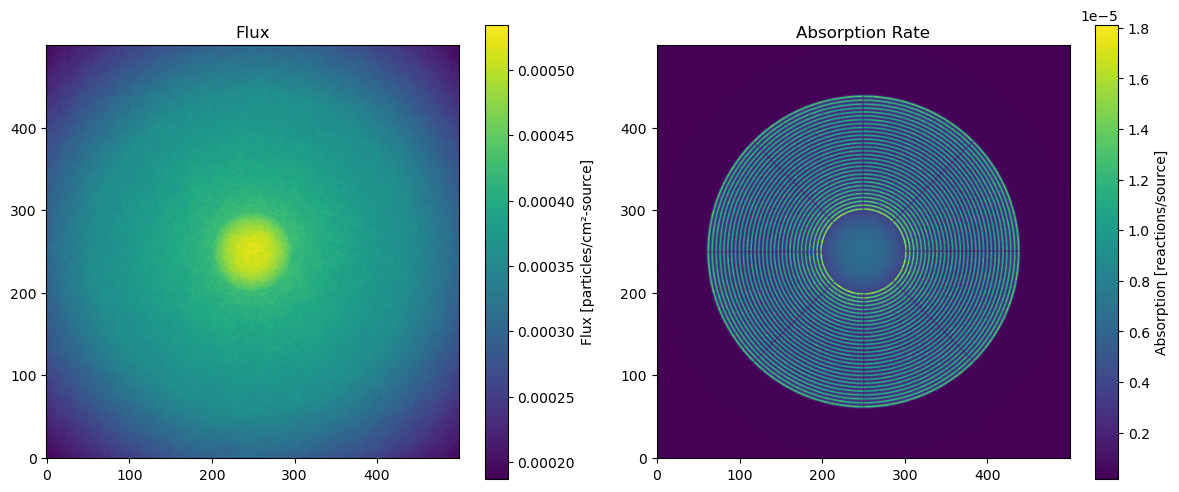

In [16]:
flux = tally.get_slice(scores=['flux'])
absorption = tally.get_slice(scores=['absorption']) - tally.get_slice(scores=['fission'])

flux.mean.shape = (500, 500)
absorption.mean.shape = (500, 500)

# 1. Create a figure and axes side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 2. Plot flux mean
im1 = ax1.imshow(flux.mean, origin="lower")
ax1.set_title("Flux")
fig.colorbar(im1, ax=ax1, label="Flux [particles/cm²-source]")

# 3. Plot absorption mean
im2 = ax2.imshow(absorption.mean, origin="lower")
ax2.set_title("Absorption Rate")
fig.colorbar(im2, ax=ax2, label="Absorption [reactions/source]")

# 4. Adjust layout and save to a file
plt.tight_layout()
plt.savefig("tally_results.png", dpi=300)
plt.show()